In [19]:
!pip -q install openai textblob mutagen

import os, glob, re
from getpass import getpass
from collections import Counter
from difflib import SequenceMatcher
import pandas as pd
import matplotlib.pyplot as plt
from openai import OpenAI
from textblob import TextBlob
from mutagen import File as MutagenFile

In [2]:
if not os.environ.get("OPENAI_API_KEY"):
    os.environ["OPENAI_API_KEY"] = getpass("Enter your OpenAI API key: ")
client = OpenAI()

Enter your OpenAI API key: ··········


In [5]:
AUDIO_DIR = "/content/sample_data/Complains"
EXTS = (".mp3", ".wav", ".m4a", ".mp4", ".webm", ".ogg", ".flac", ".mpeg", ".mpga")

files = sorted(p for p in glob.glob(f"{AUDIO_DIR}/*") if p.lower().endswith(EXTS))
print(len(files), "files found")
print(files[:3])

40 files found
['/content/sample_data/Complains/A2.ogg', '/content/sample_data/Complains/Audio1.ogg', '/content/sample_data/Complains/WhatsApp Ptt 2026-10-15 at 2.54.04 PM.ogg']


In [7]:
rows = []
for i, path in enumerate(files, 1):
    try:
        with open(path, "rb") as f:
            r = client.audio.transcriptions.create(model="whisper-1", file=f, language="en")
        rows.append({"file": os.path.basename(path), "path": path, "transcript": r.text})
        print(f"[{i}/{len(files)}] ok")
    except Exception as e:
        print(f"[{i}/{len(files)}] FAILED {os.path.basename(path)}: {e}")

df = pd.DataFrame(rows)
df.to_csv("/content/transcripts.csv", index=False)
df.head()

[1/40] ok
[2/40] ok
[3/40] ok
[4/40] ok
[5/40] ok
[6/40] ok
[7/40] ok
[8/40] ok
[9/40] ok
[10/40] ok
[11/40] ok
[12/40] ok
[13/40] ok
[14/40] ok
[15/40] ok
[16/40] ok
[17/40] ok
[18/40] ok
[19/40] ok
[20/40] ok
[21/40] ok
[22/40] ok
[23/40] ok
[24/40] ok
[25/40] ok
[26/40] ok
[27/40] ok
[28/40] ok
[29/40] ok
[30/40] ok
[31/40] ok
[32/40] ok
[33/40] ok
[34/40] ok
[35/40] ok
[36/40] ok
[37/40] ok
[38/40] ok
[39/40] ok
[40/40] ok


,file,path,transcript
0,A2.ogg,/content/sample_data/Complains/A2.ogg,There is a service phase on my invoice that I ...
1,Audio1.ogg,/content/sample_data/Complains/Audio1.ogg,I was charged twice for my monthly subscriptio...
2,WhatsApp Ptt 2026-10-15 at 2.54.04 PM.ogg,/content/sample_data/Complains/WhatsApp Ptt 20...,"I paid my bill on the 1st of the month, but I ..."
3,WhatsApp Ptt 2026-10-15 at 2.54.05 PM.ogg,/content/sample_data/Complains/WhatsApp Ptt 20...,My latest bill is almost double. What I normal...
4,WhatsApp Ptt 2026-10-15 at 2.54.06 PM.ogg,/content/sample_data/Complains/WhatsApp Ptt 20...,"The price on the website was $49, but I was ch..."


In [20]:
CATEGORIES = {
    "Billing": ["bill", "charged", "charge", "invoice", "payment", "overcharged", "price", "fee", "billing"],
    "Delivery": ["deliver", "shipping", "courier", "package", "parcel", "arrive", "tracking", "driver"],
    "Product quality": ["broken", "damaged", "defective", "quality", "cracked", "missing parts", "falling apart", "brand new", "battery", "color"],
    "Customer service": ["agent", "support", "rude", "reply", "callback", "representative", "live chat", "on hold", "responsibility"],
    "Refund/Return": ["refund", "return", "replacement", "money back", "coupon", "label"],
    "Technical issue": ["app", "log in", "login", "website", "crash", "error", "password", "froze", "verification", "notifications", "upload"],
}
def categorize(text):
    t = str(text).lower()
    scores = {c: sum(k in t for k in kws) for c, kws in CATEGORIES.items()}
    best, n = max(scores.items(), key=lambda x: x[1])
    return best if n > 0 else "Other"

def seconds(path):
    try: return float(MutagenFile(path).info.length)
    except Exception: return None

df["word_count"] = df["transcript"].str.split().str.len()
df["duration_sec"] = df["path"].apply(seconds)
df["words_per_min"] = (df["word_count"] / (df["duration_sec"] / 60)).round(1)
df["sentiment_score"] = df["transcript"].apply(lambda t: TextBlob(str(t)).sentiment.polarity)
df["sentiment"] = df["sentiment_score"].apply(lambda s: "positive" if s > 0.1 else "negative" if s < -0.1 else "neutral")
df["category"] = df["transcript"].apply(categorize)

print(f"{len(df)} complaints | {df.duration_sec.sum()/60:.1f} min of audio | avg {df.word_count.mean():.0f} words")
print(df["category"].value_counts())
print(df.groupby("category")["sentiment_score"].mean().round(2).sort_values())

40 complaints | 4.5 min of audio | avg 15 words
category
Billing            9
Delivery           9
Refund/Return      7
Product quality    6
Technical issue    6
Other              3
Name: count, dtype: int64
category
Technical issue   -0.08
Other             -0.06
Delivery          -0.04
Billing           -0.01
Refund/Return     -0.01
Product quality    0.05
Name: sentiment_score, dtype: float64


In [21]:
SCRIPT = {
 "Billing": ["I was charged twice for my monthly subscription and nobody has refunded the extra amount.",
  "My latest bill is almost double what I normally pay, and I haven't changed my plan.",
  "There is a service fee on my invoice that I never agreed to. Please explain it or remove it.",
  "I paid my bill on the first of the month, but I still got a late payment penalty.",
  "The price on the website was forty-nine dollars, but I was charged sixty-five at checkout.",
  "I cancelled my subscription last month and you are still billing my card.",
  "Your billing team keeps sending me different amounts for the same invoice, and nobody can tell me which one is correct.",
  "I was overcharged for shipping, and the discount code I used was never applied."],
 "Delivery": ["My order was supposed to arrive last Monday, and it still hasn't shown up.",
  "The tracking page has said out for delivery for three days, and nothing has arrived.",
  "The courier left my package at the wrong address, and now I can't find it.",
  "I paid extra for express shipping, and my parcel still took ten days to arrive.",
  "The delivery driver never rang the bell and marked my order as delivered.",
  "Only half of my order arrived, and the rest is apparently still in the warehouse.",
  "The package was left outside in the rain, and everything inside is soaked.",
  "Every time I contact the courier, they tell me to contact the seller, and the seller tells me to contact the courier."],
 "Product quality": ["The phone I received has a cracked screen right out of the box.",
  "The blender stopped working after just two days. It is clearly defective.",
  "The shirt looks nothing like the photos, and the fabric is really poor quality.",
  "The item arrived with missing parts, so I can't even use it.",
  "The laptop battery drains in under an hour, which is nowhere near what the description promised.",
  "The shoes started falling apart after one week of normal use.",
  "I received a used product that was sold to me as brand new.",
  "The color is completely different from what is shown online. I am very disappointed."],
 "Customer service": ["I have called your support line four times, and each time I was on hold for more than forty minutes.",
  "The agent I spoke with was rude and hung up on me in the middle of the call.",
  "I sent three emails last week and haven't received a single reply.",
  "Every agent tells me something different, and nobody takes responsibility for my case.",
  "I was promised a callback within twenty-four hours, and it has been a week.",
  "The live chat kept disconnecting before my problem was solved.",
  "Nobody at your company knows about my previous complaint, so I had to explain everything again.",
  "The representative was polite, but he couldn't solve my problem, and I am still waiting."],
 "Refund/Return": ["I returned my order a month ago, and I still haven't received my refund.",
  "Your return policy says thirty days, but you rejected my return on day twenty-five.",
  "I asked for a replacement, and instead you sent me a coupon that I don't want.",
  "I want my money back because the product is not what was advertised.",
  "My refund was approved two weeks ago, but the money has not appeared in my account.",
  "I was told I would get a prepaid return label, and it never arrived.",
  "I cancelled my order within five minutes, and you still shipped it.",
  "You refunded only half of the amount and gave me no explanation."],
 "Technical issue": ["The app crashes every time I try to open my order history.",
  "I can't log in to my account, and the password reset email never arrives.",
  "The website froze at checkout and I lost everything in my cart.",
  "After the latest update, the app is slower and keeps logging me out.",
  "The payment page showed an error message, but my card was still charged.",
  "The mobile app doesn't send me notifications about my orders anymore.",
  "I keep receiving verification codes that don't work.",
  "Your website won't let me upload my invoice. It just says something went wrong."],
 "Other": ["I am writing to complain about your new packaging. It is wasteful and impossible to open.",
  "I have been a loyal customer for five years, but this experience has made me seriously consider switching to another company."],
}
script = pd.DataFrame([(c, t) for c, ts in SCRIPT.items() for t in ts], columns=["true_category", "text"])

norm = lambda s: re.sub(r"[^a-z0-9' ]+", "", str(s).lower()).strip()

def best_match(transcript):
    scores = [SequenceMatcher(None, norm(t), norm(transcript)).ratio() for t in script["text"]]
    i = max(range(len(scores)), key=scores.__getitem__)
    return pd.Series({"matched_idx": i, "original_text": script.loc[i, "text"],
                      "true_category": script.loc[i, "true_category"],
                      "transcription_accuracy": scores[i]})

m = pd.concat([df, df["transcript"].apply(best_match)], axis=1)

print(f"Files: {len(m)} | unique sentences matched: {m.matched_idx.nunique()}")
print(f"Transcription accuracy: {m.transcription_accuracy.mean()*100:.1f}%")
print(f"Category accuracy: {(m.category == m.true_category).mean()*100:.1f}%")

display(m[m.transcription_accuracy < 0.6][["file", "transcript", "original_text", "transcription_accuracy"]])
pd.crosstab(m.true_category, m.category)

Files: 40 | unique sentences matched: 40
Transcription accuracy: 96.9%
Category accuracy: 92.5%


,file,transcript,original_text,transcription_accuracy


category,Billing,Delivery,Other,Product quality,Refund/Return,Technical issue
true_category,,,,,,
Billing,8,0,0,0,0,0
Delivery,0,8,0,0,0,0
Other,0,0,2,0,0,0
Product quality,0,1,0,6,0,0
Refund/Return,0,0,1,0,7,0
Technical issue,1,0,0,0,0,6


In [22]:
m[m.category != m.true_category][["transcript", "true_category", "category"]]

,transcript,true_category,category
20,"The item arrived with the missing part, so I c...",Product quality,Delivery
27,I cancelled my order within five minutes. You ...,Refund/Return,Other
37,The payment page showed an error message but m...,Technical issue,Billing


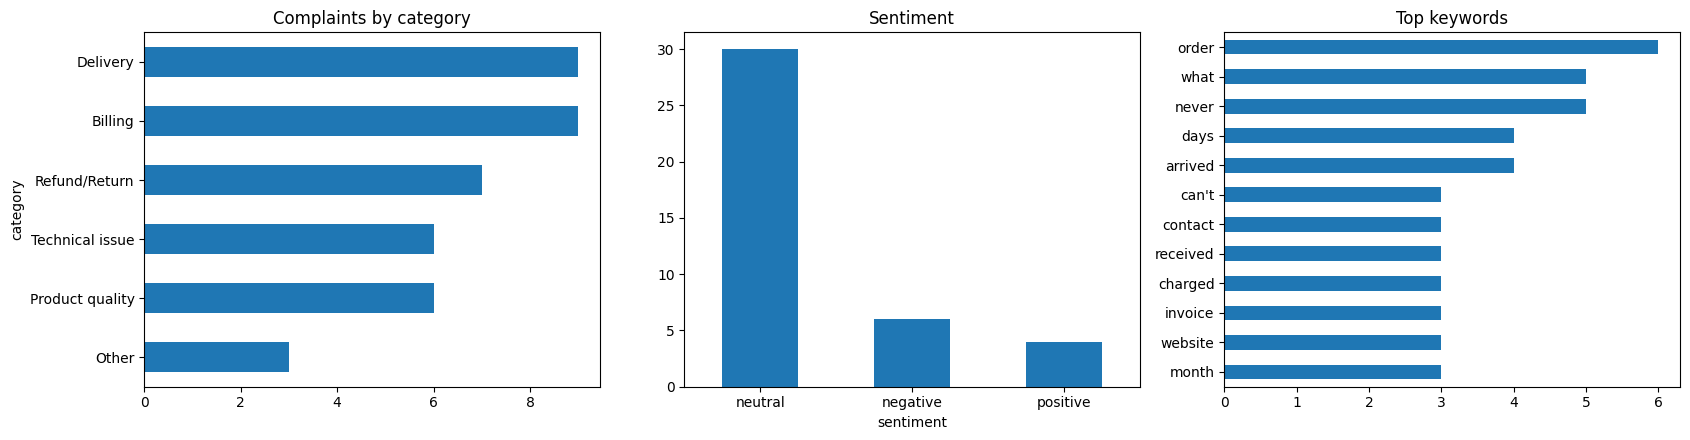

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
m["category"].value_counts().sort_values().plot.barh(ax=ax[0], title="Complaints by category")
m["sentiment"].value_counts().plot.bar(ax=ax[1], title="Sentiment", rot=0)

STOP = set("the a an and is to of in it i you that this for on with are was my me be have has had but not so at as or can will than been from your our we they do did very just all up out if when i'm still".split())
words = [w for w in re.findall(r"[a-z']+", " ".join(m.transcript.astype(str)).lower()) if w not in STOP and len(w) > 2]
pd.Series(Counter(words)).sort_values().tail(12).plot.barh(ax=ax[2], title="Top keywords")
plt.tight_layout(); plt.savefig("/content/summary.png", dpi=150); plt.show()

m.to_csv("/content/analysis_results.csv", index=False)
from google.colab import files as colab_files
colab_files.download("/content/analysis_results.csv")
colab_files.download("/content/summary.png")